In [298]:
import pandas as pd

print("Retail Sales Analysis Project Started!")

Retail Sales Analysis Project Started!


In [299]:
import os

print("Current Location:", os.getcwd())
print("Files Available:", os.listdir())

Current Location: c:\Users\Admin\OneDrive\Desktop\python\set start\DataAnalytics-L1-EDARetailSales
Files Available: ['retail_sales_analysis.ipynb', 'retail_sales_dataset.csv.txt']


In [300]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv.txt")

display(df.head())

,Transaction ID\tDate\tCustomer ID\tGender\tAge\tProduct Category\tQuantity\tPrice per Unit\tTotal Amount
0,1\t24-11-2023\tCUST001\tMale\t34\tBeauty\t3\t5...
1,2\t27-02-2023\tCUST002\tFemale\t26\tClothing\t...
2,3\t13-01-2023\tCUST003\tMale\t50\tElectronics\...
3,4\t21-05-2023\tCUST004\tMale\t37\tClothing\t1\...
4,5\t06-05-2023\tCUST005\tMale\t30\tBeauty\t2\t5...


In [301]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv.txt", sep="\t")

display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24-11-2023,CUST001,Male,34,Beauty,3,50,150
1,2,27-02-2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13-01-2023,CUST003,Male,50,Electronics,1,30,30
3,4,21-05-2023,CUST004,Male,37,Clothing,1,500,500
4,5,06-05-2023,CUST005,Male,30,Beauty,2,50,100


In [302]:
print(df.shape)
print(df.columns.tolist())

(1000, 9)
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [303]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [304]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [305]:
print(df.dtypes)

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object


In [306]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

print(df.dtypes)

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [307]:
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [308]:
category_sales = df.groupby("Product Category")["Total Amount"].sum()

print(category_sales)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


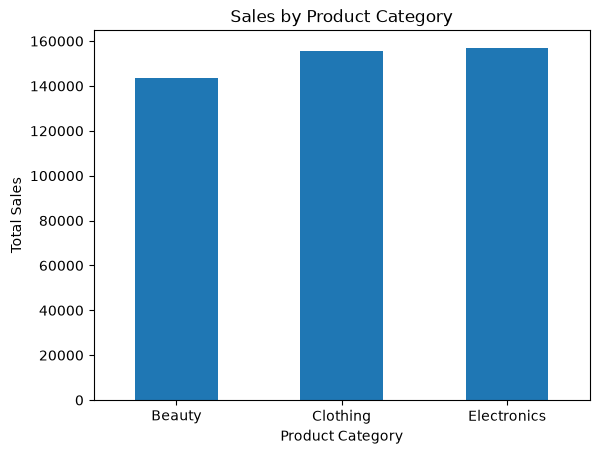

In [309]:
import matplotlib.pyplot as plt

category_sales.plot(kind="bar")

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()

In [310]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


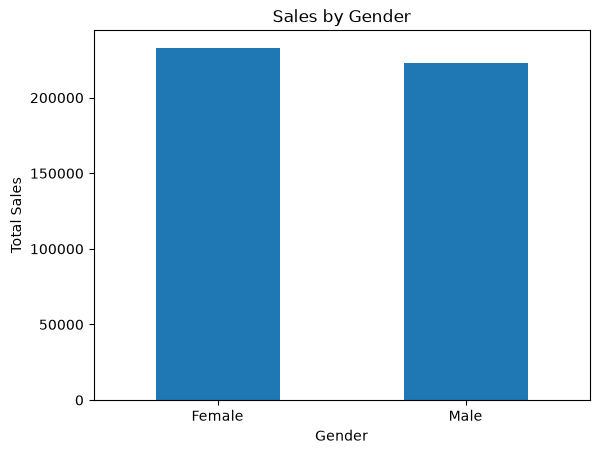

In [311]:
gender_sales.plot(kind="bar")

plt.title("Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()

In [312]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

print(df[["Age", "Age Group"]].head(10))

   Age Age Group
0   34     26-35
1   26     26-35
2   50     46-55
3   37     36-45
4   30     26-35
5   45     36-45
6   46     46-55
7   30     26-35
8   63     56-65
9   52     46-55


In [313]:
age_sales = df.groupby("Age Group", observed=True)["Total Amount"].sum()

print(age_sales)

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-65     80410
Name: Total Amount, dtype: int64


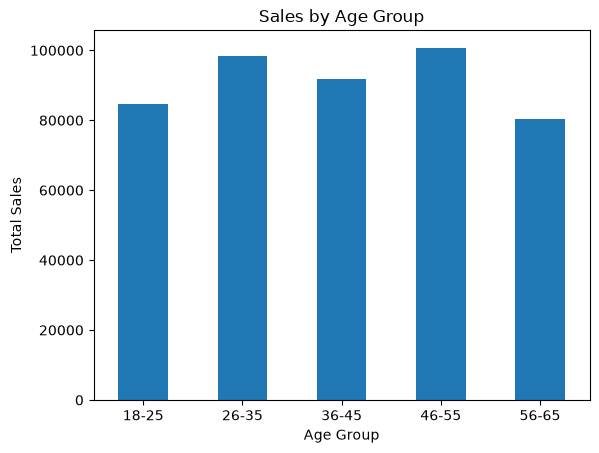

In [314]:
age_sales.plot(kind="bar")

plt.title("Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()

In [315]:
df["Month"] = df["Date"].dt.month

monthly_sales = df.groupby("Month")["Total Amount"].sum()

print(monthly_sales)


Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


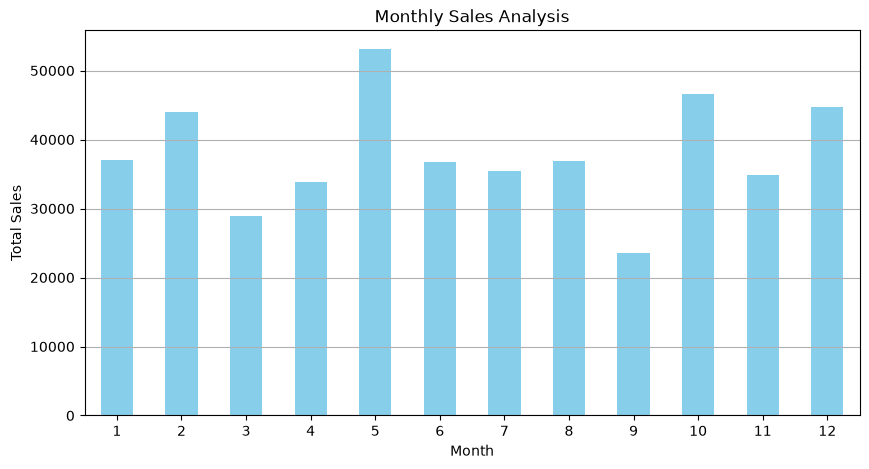

In [316]:
plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="bar", color="skyblue")

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [317]:
category_sales = df.groupby("Product Category")["Total Amount"].sum()

print(category_sales)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


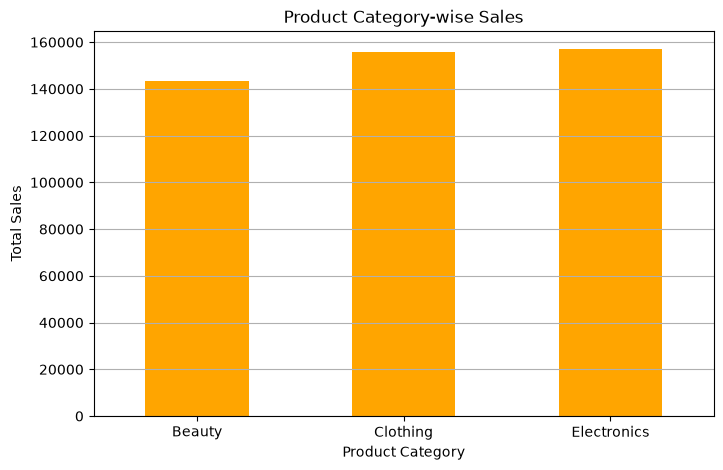

In [318]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar", color="orange")

plt.title("Product Category-wise Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


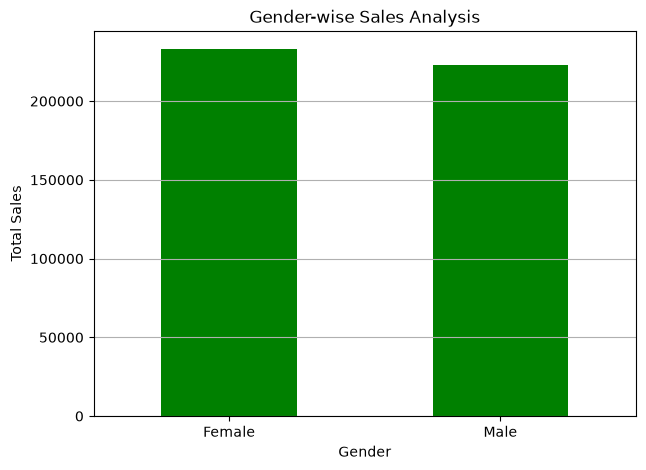

In [319]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print(gender_sales)

plt.figure(figsize=(7, 5))

gender_sales.plot(kind="bar", color="green")

plt.title("Gender-wise Sales Analysis")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-65     80410
Name: Total Amount, dtype: int64


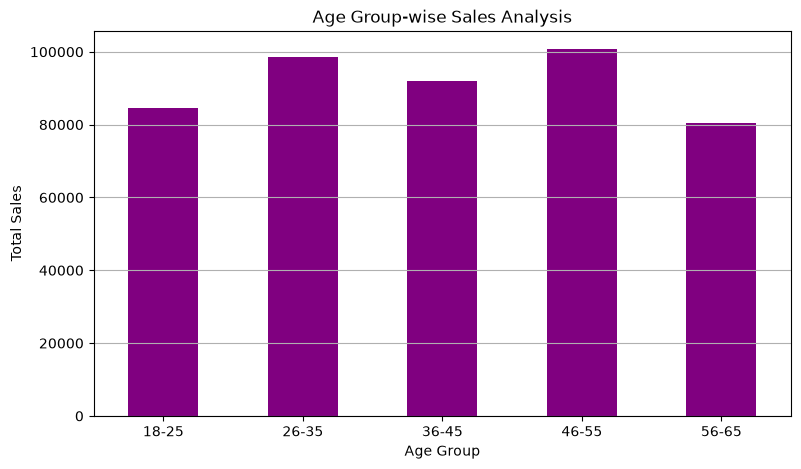

In [320]:
age_sales = df.groupby("Age Group", observed=False)["Total Amount"].sum()

print(age_sales)

plt.figure(figsize=(9, 5))

age_sales.plot(kind="bar", color="purple")

plt.title("Age Group-wise Sales Analysis")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

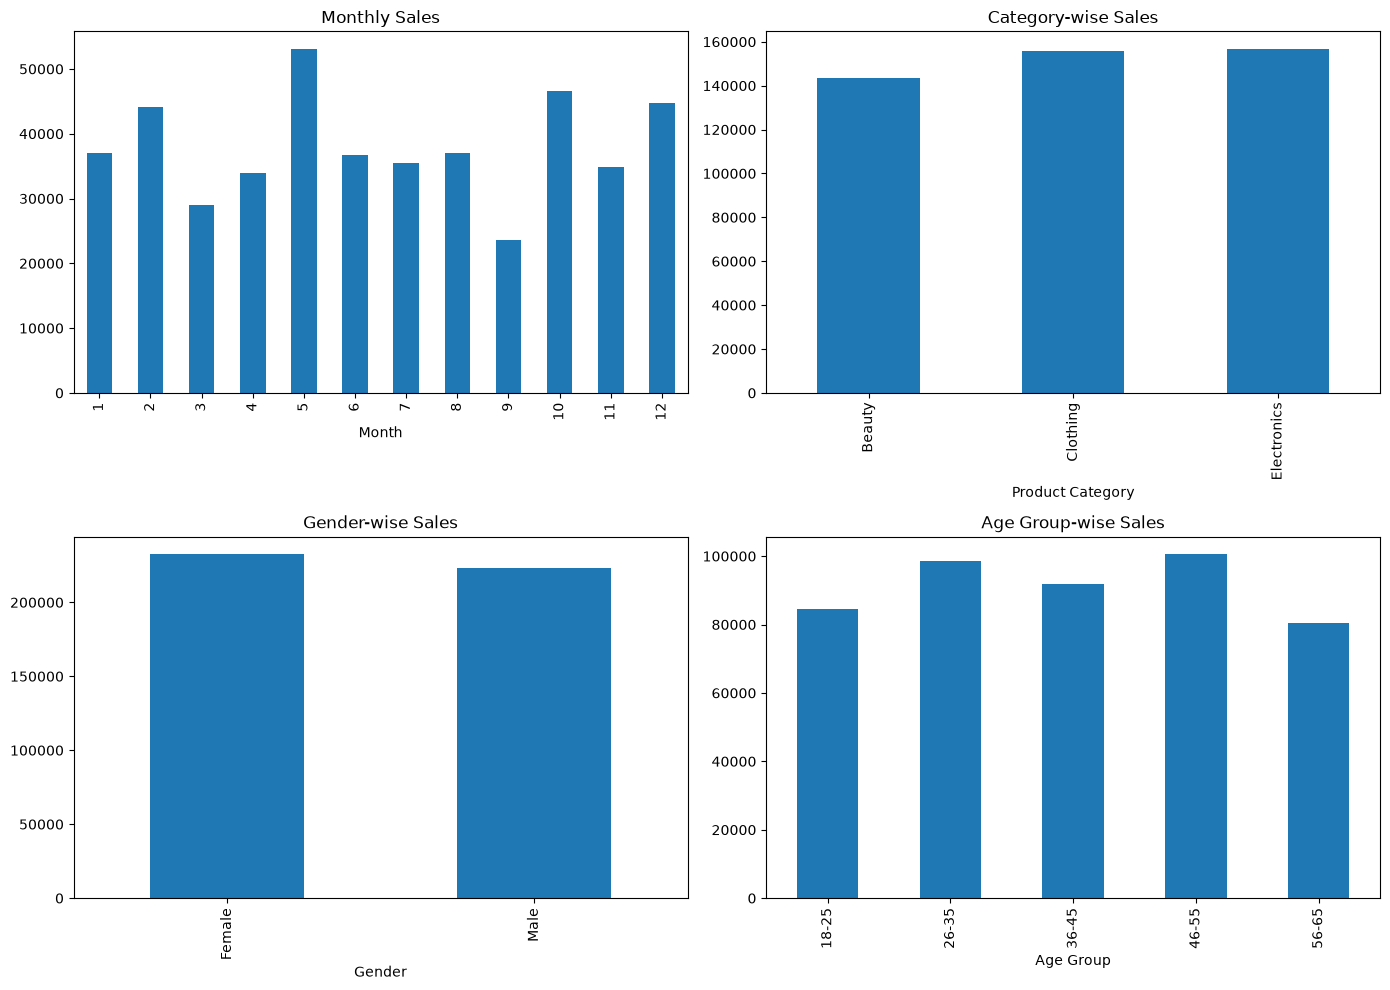

In [321]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Monthly Sales
monthly_sales.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Monthly Sales")

# Category Sales
category_sales.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Category-wise Sales")

# Gender Sales
gender_sales.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Gender-wise Sales")

# Age Group Sales
age_sales.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Age Group-wise Sales")

plt.tight_layout()
plt.show()